# Optical tweezers: trapping a bead in a laser focus

Light carries momentum: a beam of power $P$ in a medium of index $n_m$
carries the momentum flux $n_mP/c$. A transparent bead refracts the light
that passes through it, changes the direction of that momentum, and feels
the opposite change as a force. In a weakly focused beam the bead is
simply pushed along (Ashkin 1970). In the focus of a high NA objective,
the steep rays that the bead bends towards the axis pull it back towards
the focus, strongly enough to hold it against the push of the light that
it reflects and scatters. That is the single-beam gradient trap (Ashkin,
Dziedzic, Bjorkholm and Chu 1986), the optical tweezers of biophysics,
with forces of piconewtons and spring constants of some 0.1 pN/nm per watt.

Forces are given here as dimensionless **trapping efficiencies**
$Q = Fc/(n_mP)$: the fraction of the beam's momentum flux that is
transferred to the bead. With $P = 10$ mW in water, $Q = 0.1$ is
4.4 pN. The notebook compares three models of the force, all from
`pyoptics.tweezers`:

1. **one ray** hitting a sphere: Ashkin's closed form scattering and
   gradient efficiencies, summed over all internal reflections, against an
   explicit trace of the reflections,
2. **a fan of rays** from the pupil of an aplanatic objective (Ashkin's
   ray optics model, valid for beads much larger than the wavelength):
   where the bead sits, which rays push and which pull, and the force field
   around the focus,
3. **waves**: the Richards–Wolf focus as a sum of plane waves, each
   scattered exactly by the sphere (Mie theory), and the force from the
   momentum that leaves through a sphere far away (the Maxwell stress
   tensor at infinity). Checks: the dipole (Rayleigh) force on small beads
   and the radiation pressure of a plane wave on large ones,
4. rays against waves for beads from 0.1 to 3 µm radius,
5. potential wells, Brownian motion in the trap, the calibration of the
   trap by its power spectrum, and thermal escape over the axial barrier
   against Kramers' rate,
6. trap stiffness against bead size and NA,
7. when the bead escapes: low NA, underfilled pupils and high index beads.

The focus is that of notebook 02 (vectorial diffraction); the Mie series
are those of notebook 71 (`analytical.mie_amplitudes()`).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.interpolate import CubicSpline
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import curve_fit
from scipy.signal import welch

from pyoptics import sketch, tweezers as tw

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
BLUE, RED, GREEN, GREY, ORANGE = "#2a7ab9", "#d6604d", "#5aa469", "0.45", "#e0a000"
UM = 1e-6
WL = 1.064e-6                 # Nd:YAG laser
N_W = 1.33                    # water
N_PS, N_SIO2 = 1.57, 1.45     # polystyrene, silica
NA = 1.2                      # water immersion objective
FILL = 1.0                    # Gaussian beam radius = pupil radius
T_K = 295.0
ETA = 0.95e-3                 # viscosity of water at 22 °C (Pa s)
KT = tw.K_B*T_K
UNIT = N_W/tw.C_LIGHT         # force per watt for Q = 1 (N/W)
rng = np.random.default_rng(75)
t_start = time.time()


def on_axis(z):
    z = np.atleast_1d(z)
    return np.stack([0*z, 0*z, z], axis=-1)


def along_x(x, z0=0.0, axis=0):
    x = np.atleast_1d(x)
    r = np.zeros((len(x), 3))
    r[:, axis] = x
    r[:, 2] = z0
    return r


def wave_trap(radius, n_sph=N_PS, NA=NA, filling=FILL, max_offset=None, polarization="x"):
    return tw.MieTrap(radius, n_sph, WL, NA, N_W, filling=filling, polarization=polarization,
                      max_offset=max_offset)


def trap_point(force, radius, z_lo=None, z_hi=None):
    """Axial equilibrium and spring constants (Q per metre) of a force(r) in Q."""
    z_lo = -0.3*radius if z_lo is None else z_lo
    z_hi = 1.2*radius + 0.6*UM if z_hi is None else z_hi
    z_eq = tw.equilibrium(lambda z: force(np.array([0, 0, z]))[2], z_lo, z_hi, num=17)
    if z_eq is None:
        return None, np.full(3, np.nan)
    return z_eq, tw.stiffness(force, [0, 0, z_eq], 0.02*radius + 5e-9)

A typical setup: an infrared laser (little absorption in water and
biological samples), expanded so that it overfills the back aperture of
a water immersion objective, a sample chamber in which the beads float,
and a condenser that sends the light onto a quadrant photodiode. The
photodiode sees the interference of the light scattered by the bead with
the unscattered beam and measures the bead's position to nanometres.

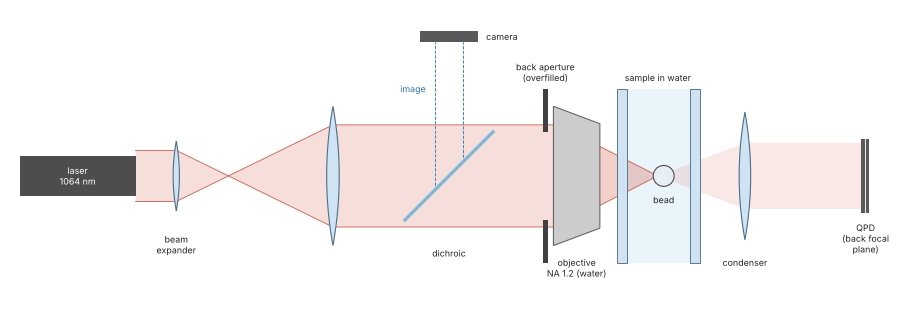

In [2]:
fig, ax = plt.subplots(figsize=(13, 4.0), layout="constrained")
sketch.optical_tweezers(ax)

## 1. One ray: Ashkin's scattering and gradient efficiencies

A ray of power $P$ hits a sphere at the angle of incidence $\theta$. A
fraction $R$ (Fresnel) is reflected, the rest is refracted into the
sphere at the angle $r$, hits the far side, where again $R$ is reflected
inside and $T = 1 - R$ leaves, and so on. Adding up the momentum of all
rays that leave, each turned by $\pi + 2\theta - 2r$ against the one
before, gives a geometric series with Ashkin's closed forms (1992)
for the force along the incident ray (scattering, $Q_s$) and
perpendicular to it in the plane of incidence (gradient, $Q_g$):

$$Q_s = 1 + R\cos 2\theta - T^2\frac{\cos(2\theta - 2r) + R\cos 2\theta}{1 + R^2 + 2R\cos 2r},\qquad
  Q_g = -R\sin 2\theta + T^2\frac{\sin(2\theta - 2r) + R\sin 2\theta}{1 + R^2 + 2R\cos 2r}.$$

$Q_g > 0$ pulls the sphere towards the ray (`tweezers.ashkin_efficiencies()`).
`traced_efficiencies()` follows the ray through 200 internal reflections
instead and sums the momenta of the rays that leave, with the same Fresnel
coefficients.

closed form against the traced series: max deviation 3.9e-16
n_rel = 1.2, circular: largest Q_g = 0.506 at θ = 72°


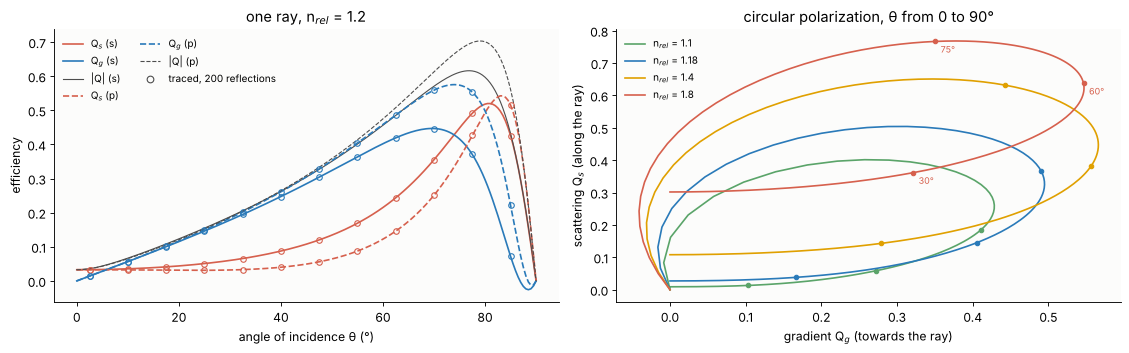

In [3]:
theta = np.linspace(0, np.pi/2, 181)
theta_pts = np.deg2rad(np.arange(2.5, 90, 7.5))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), layout="constrained")
dev = 0.0
for pol, ls in [("s", "-"), ("p", "--")]:
    qs, qg = tw.ashkin_efficiencies(theta, 1.2, pol)
    ax[0].plot(np.rad2deg(theta), qs, ls=ls, color=RED, label="Q$_s$ ({})".format(pol))
    ax[0].plot(np.rad2deg(theta), qg, ls=ls, color=BLUE, label="Q$_g$ ({})".format(pol))
    ax[0].plot(np.rad2deg(theta), np.hypot(qs, qg), ls=ls, color="0.3", lw=1, label="|Q| ({})".format(pol))
    tr = np.array([tw.traced_efficiencies(th, 1.2, pol, 200) for th in theta_pts])
    ax[0].plot(np.rad2deg(theta_pts), tr[:, 0], "o", color=RED, mfc="none", ms=5)
    ax[0].plot(np.rad2deg(theta_pts), tr[:, 1], "o", color=BLUE, mfc="none", ms=5)
    dev = max(dev, np.max(np.abs(tr - np.array(tw.ashkin_efficiencies(theta_pts, 1.2, pol)).T)))
ax[0].plot([], [], "o", color="0.3", mfc="none", label="traced, 200 reflections")
ax[0].set_xlabel("angle of incidence θ (°)"); ax[0].set_ylabel("efficiency")
ax[0].set_title("one ray, n$_{rel}$ = 1.2")
ax[0].legend(frameon=False, fontsize=9, ncol=2)
for n_rel, col in [(1.1, GREEN), (1.18, BLUE), (1.4, ORANGE), (1.8, RED)]:
    qs, qg = tw.ashkin_efficiencies(theta, n_rel, "circular")
    ax[1].plot(qg, qs, color=col, label="n$_{{rel}}$ = {}".format(n_rel))
    for deg in (30, 60, 75):
        i = np.argmin(np.abs(np.rad2deg(theta) - deg))
        ax[1].plot(qg[i], qs[i], "o", color=col, ms=4)
        if n_rel == 1.8:
            ax[1].annotate("{}°".format(deg), (qg[i], qs[i]), textcoords="offset points", xytext=(5, -10),
                           fontsize=8, color=col)
ax[1].set_xlabel("gradient Q$_g$ (towards the ray)"); ax[1].set_ylabel("scattering Q$_s$ (along the ray)")
ax[1].set_title("circular polarization, θ from 0 to 90°")
ax[1].legend(frameon=False, fontsize=9)
print("closed form against the traced series: max deviation {:.1e}".format(dev))
print("n_rel = 1.2, circular: largest Q_g = {:.3f} at θ = {:.0f}°".format(
    np.max(tw.ashkin_efficiencies(theta, 1.2, "circular")[1]),
    np.rad2deg(theta[np.argmax(tw.ashkin_efficiencies(theta, 1.2, "circular")[1])])))

The closed form and the traced series agree to round-off. Gradient and
scattering efficiency are of the same size: a single steep ray pulls the
sphere sideways towards itself about as much as it pushes it forward.
A trap works only if, summed over the rays of the focus, the pull of the
steep rays towards the focus beats the forward push of all of them. On
the right, the higher the index ratio, the more the curves move up (more
reflection, more push) at large angles; for $n_{rel} = 1.8$ the steep rays
mostly push.

## 2. A fan of rays: Ashkin's trap

The objective turns the collimated beam into rays that converge towards
the focus $f$, each under its pupil angle $\theta$ (sine condition) with
the power that the pupil illumination gives it (`ray_optics_force()`). A
ray that hits the bead is split into its s and p parts for its own plane
of incidence; behind the lens an $x$ polarized beam is polarized along
$\cos\phi\,\mathbf e_\theta - \sin\phi\,\mathbf e_\phi$. The sketches show
Ashkin's picture with two rays: before the focus the bead is pushed
forward towards it, beyond the focus the rays leave the bead *more
parallel* to the axis than they came in and pull it back, and beside the
axis the net force points towards the axis. Only the forces of
refraction are drawn; reflection adds a forward push.

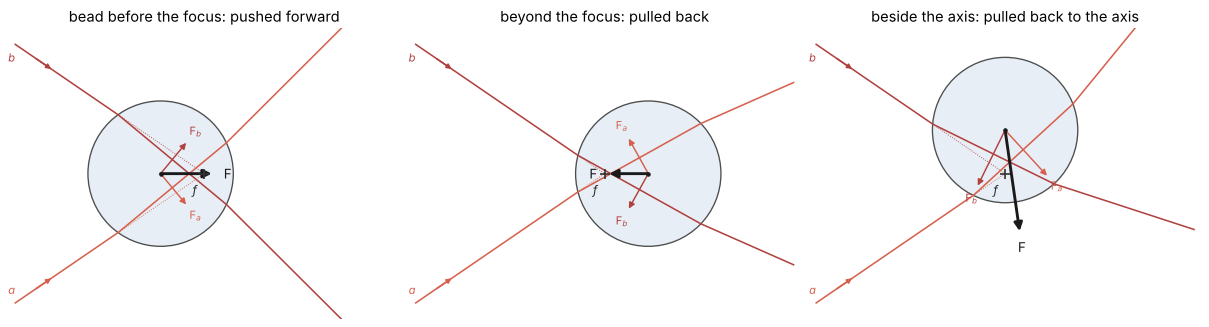

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
for ax, off, title in zip(axs, [(-0.6, 0.0), (0.6, 0.0), (0.0, 0.6)],
                          ["bead before the focus: pushed forward", "beyond the focus: pulled back",
                           "beside the axis: pulled back to the axis"]):
    sketch.ashkin_rays(ax, offset=off, title=title)

In ray optics the efficiency depends only on the position in units of the
bead radius $a$, not on its size. The curves below are for polystyrene in
water ($n_{rel} = 1.18$) in the focus of a water immersion objective with
NA 1.2, filled by a Gaussian beam whose radius equals that of the pupil
(the default throughout), against a uniformly lit and an underfilled pupil.

uniform pupil                     : z_eq = 0.170 a, largest backward Q_z = 0.129, largest lateral Q_x = 0.412


Gaussian, w = pupil radius        : z_eq = 0.275 a, largest backward Q_z = 0.076, largest lateral Q_x = 0.451


Gaussian, w = 0.5 × pupil radius  : z_eq = 0.870 a, largest backward Q_z = 0.012, largest lateral Q_x = 0.290


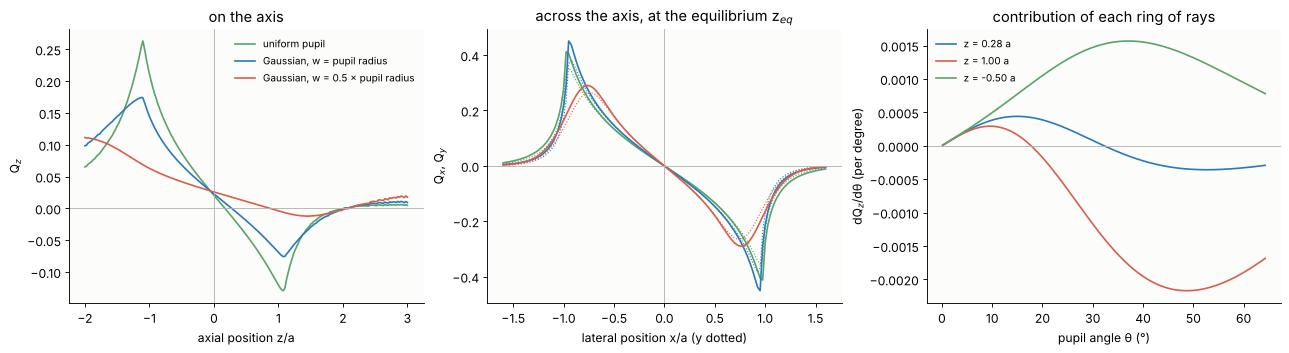

In [5]:
z_r = np.linspace(-2, 3, 201)
x_r = np.linspace(-1.6, 1.6, 129)
ray_curves = {}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), layout="constrained")
for fill, col, lab in [(None, GREEN, "uniform pupil"), (1.0, BLUE, "Gaussian, w = pupil radius"),
                       (0.5, RED, "Gaussian, w = 0.5 × pupil radius")]:
    qz = tw.ray_optics_force(on_axis(z_r), 1.0, N_PS, NA, N_W, filling=fill)[:, 2]
    i = np.nonzero((qz[:-1] > 0) & (qz[1:] <= 0))[0][0]
    z_eq = z_r[i] - qz[i]*(z_r[i + 1] - z_r[i])/(qz[i + 1] - qz[i])
    qx = tw.ray_optics_force(along_x(x_r, z_eq), 1.0, N_PS, NA, N_W, filling=fill)
    qy = tw.ray_optics_force(along_x(x_r, z_eq, axis=1), 1.0, N_PS, NA, N_W, filling=fill)
    ray_curves[fill] = (qz, qx[:, 0], qy[:, 1], z_eq)
    ax[0].plot(z_r, qz, color=col, label=lab)
    ax[1].plot(x_r, qx[:, 0], color=col, label=lab)
    ax[1].plot(x_r, qy[:, 1], color=col, ls=":", lw=1)
    print("{:34s}: z_eq = {:.3f} a, largest backward Q_z = {:.3f}, largest lateral Q_x = {:.3f}".format(
        lab, z_eq, -qz.min(), qx[:, 0].max()))
for a_ in ax[:2]:
    a_.axhline(0, color="0.7", lw=0.8)
    a_.axvline(0, color="0.7", lw=0.8)
ax[0].set_xlabel("axial position z/a"); ax[0].set_ylabel("Q$_z$")
ax[0].set_title("on the axis"); ax[0].legend(frameon=False, fontsize=9)
ax[1].set_xlabel("lateral position x/a (y dotted)"); ax[1].set_ylabel("Q$_x$, Q$_y$")
ax[1].set_title("across the axis, at the equilibrium z$_{eq}$")
# which rays push and which pull: contribution per ring of the pupil
z_eq = ray_curves[1.0][3]
for zz, col in [(z_eq, BLUE), (1.0, RED), (-0.5, GREEN)]:
    _, th_r, q_rays = tw.ray_optics_force(np.array([0, 0, zz]), 1.0, N_PS, NA, N_W, per_ray=True)
    th_u = np.unique(th_r)
    ring = np.array([q_rays[th_r == v, 2].sum() for v in th_u])/(th_u[1] - th_u[0])/np.rad2deg(1)
    ax[2].plot(np.rad2deg(th_u), ring, color=col, label="z = {:.2f} a".format(zz))
ax[2].axhline(0, color="0.7", lw=0.8)
ax[2].set_xlabel("pupil angle θ (°)"); ax[2].set_ylabel("dQ$_z$/dθ (per degree)")
ax[2].set_title("contribution of each ring of rays")
ax[2].legend(frameon=False, fontsize=9)

The bead sits slightly beyond the focus, where the push of the light it
reflects balances the pull of the refracted rays. The ring contributions
show why a high NA and an overfilled pupil matter: the central rays
(small $\theta$) only push, the rays beyond about 40° pull back. An
underfilled pupil puts little power into the steep rays; its trap is
shallow and far beyond the focus (red). Laterally the trap is about
twice as strong as axially, and slightly stiffer across the polarization
(along $y$, dotted) than along it, because p polarized rays are reflected
less.

The force field in the $xz$ plane: arrows show the direction, colour the
size of $Q$. The bead is pulled into the focus from all sides except from
far beyond it, where the light pushes it out of the trap.

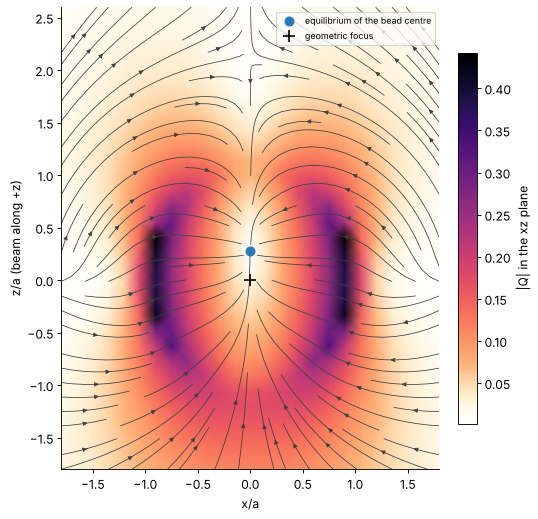

In [6]:
xg = np.linspace(-1.8, 1.8, 25)
zg = np.linspace(-1.8, 2.6, 31)
XG, ZG = np.meshgrid(xg, zg)
Q_map = tw.ray_optics_force(np.stack([XG, 0*XG, ZG], axis=-1), 1.0, N_PS, NA, N_W)
fig, ax = plt.subplots(figsize=(6.5, 6.4), layout="constrained")
mag = np.hypot(Q_map[..., 0], Q_map[..., 2])
im = ax.pcolormesh(xg, zg, mag, cmap=LIGHT, shading="gouraud")
ax.streamplot(xg, zg, Q_map[..., 0], Q_map[..., 2], color="0.25", density=1.1, linewidth=0.7,
              arrowsize=0.8)
ax.plot(0, ray_curves[1.0][3], "o", color=BLUE, ms=8, label="equilibrium of the bead centre")
ax.plot(0, 0, "+", color="k", ms=10, mew=1.5, label="geometric focus")
ax.set_xlabel("x/a"); ax.set_ylabel("z/a (beam along +z)")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=8, frameon=True)
plt.colorbar(im, ax=ax, label="|Q| in the xz plane", shrink=0.8)

## 3. Waves: the focus as plane waves and the momentum balance far away

Ray optics fails for beads of the size of the wavelength, which are those
used in practice (0.5 to 2 µm diameter). The exact force follows from the
field around the bead. The focus of an aplanatic objective is the
Richards–Wolf integral, a superposition of plane waves from the pupil,

$$\mathbf E(\mathbf r) = \int_{\Omega_{NA}} A(\theta)\sqrt{\cos\theta}\;
  \mathbf e(\theta, \phi)\,e^{ik\hat{\mathbf u}\cdot\mathbf r}\,d\Omega,$$

evaluated by a Gauss-Legendre quadrature over the pupil
(`focus_plane_waves()`, `focus_field()`). Notebook 02 computes the same
focus with FFTs. Each plane wave is scattered by the sphere as in Mie
theory (amplitudes $S_1$, $S_2$, `analytical.mie_amplitudes()`), with the
phase that it has at the bead's centre. Instead of integrating the Maxwell
stress tensor over the bead's surface, `MieTrap` integrates it over a
sphere *far away*, where it becomes a momentum flux $n_m|\mathbf E|^2/(2Zc)$
along each direction. The incoming beam is the same with or without the
bead, so the force is the outgoing momentum lost:

$$Q = -\frac{\oint\left(2\,\mathrm{Re}\,\mathbf E_{inc}^*\cdot\mathbf E_{s} + |\mathbf E_s|^2\right)
  \hat{\mathbf u}\,d\Omega}{\oint|\mathbf E_{inc}|^2\,d\Omega},$$

where the focused beam leaves the focus as the outgoing wave
$-i(2\pi/k)A\sqrt{\cos\theta}\,\mathbf e\,e^{ikr}/r$ inside the cone of the
objective. The interference term takes momentum out of the beam
(extinction), the second one is the light scattered into all directions.
This is the simplest form of the generalized Lorenz–Mie theory, exact for
any bead size, at the cost of many plane waves for large beads.

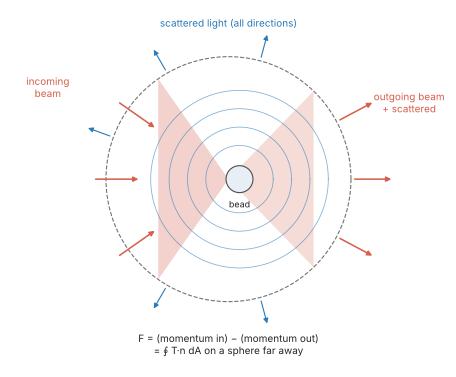

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.6), layout="constrained")
sketch.momentum_balance(ax)

The focus for NA 1.2 in water, with the $x$ polarized beam that fills the
pupil: the spot is longer along the polarization, and the focus is about
three times longer than wide.

focal spot FWHM: x 600 nm, y 450 nm, z 1350 nm (λ/(2NA) = 443 nm)


Text(0.5, 1.0, '|E|² in the focal plane')

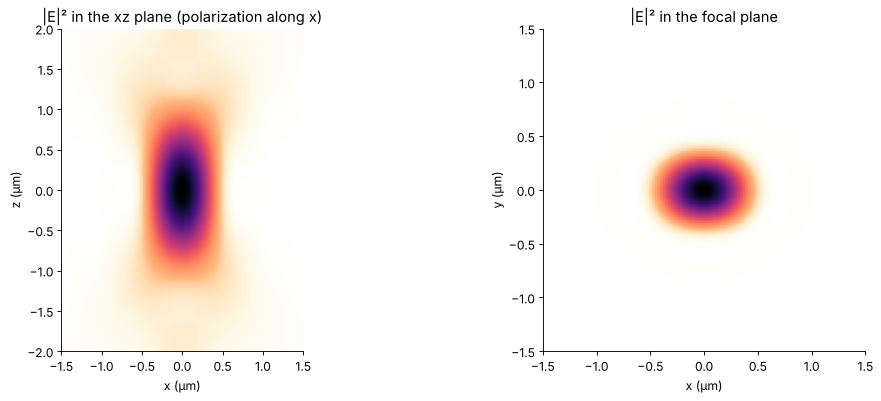

In [8]:
pw = tw.focus_plane_waves(NA, N_W, 40, 96, FILL, "x")
xf = np.linspace(-1.5, 1.5, 121)*UM
zf = np.linspace(-2.0, 2.0, 161)*UM
E_xz, _ = tw.focus_field(np.stack(np.meshgrid(xf, 0.0, zf, indexing="ij"), axis=-1)[:, 0], WL, pw, N_W)
E_xy, _ = tw.focus_field(np.stack(np.meshgrid(xf, xf, 0.0, indexing="ij"), axis=-1)[..., 0, :], WL, pw, N_W)
I_xz = np.sum(np.abs(E_xz)**2, axis=-1)
I_xy = np.sum(np.abs(E_xy)**2, axis=-1)
I0 = I_xy.max()


def fwhm(x, y):
    above = x[y >= y.max()/2]
    return above[-1] - above[0]


i0 = len(xf)//2
print("focal spot FWHM: x {:.0f} nm, y {:.0f} nm, z {:.0f} nm (λ/(2NA) = {:.0f} nm)".format(
    fwhm(xf, I_xy[:, i0])*1e9, fwhm(xf, I_xy[i0, :])*1e9, fwhm(zf, I_xz[i0, :])*1e9, WL/(2*NA)*1e9))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.9), layout="constrained", width_ratios=[1.35, 1])
ax[0].imshow((I_xz/I0).T, extent=[xf[0]/UM, xf[-1]/UM, zf[0]/UM, zf[-1]/UM], cmap=LIGHT, aspect="equal")
ax[0].set_xlabel("x (µm)"); ax[0].set_ylabel("z (µm)")
ax[0].set_title("|E|² in the xz plane (polarization along x)")
ax[1].imshow((I_xy/I0).T, extent=[xf[0]/UM, xf[-1]/UM, xf[0]/UM, xf[-1]/UM], cmap=LIGHT)
ax[1].set_xlabel("x (µm)"); ax[1].set_ylabel("y (µm)"); ax[1].set_title("|E|² in the focal plane")

**Check 1: small beads.** A sphere much smaller than the wavelength is a
dipole $\mathbf p = \alpha\mathbf E$, with the Clausius–Mossotti
polarizability and the radiative correction
$\alpha = \alpha_0/(1 - ik^3\alpha_0/6\pi\varepsilon_0n_m^2)$
(`polarizability()`). Its force (`dipole_force()`,
Chaumet and Nieto-Vesperinas 2000) is

$$F_l = \tfrac12\mathrm{Re}\sum_i\alpha E_i\,\partial_l E_i^*
  = \underbrace{\tfrac14\mathrm{Re}\,\alpha\;\partial_l|\mathbf E|^2}_{\text{gradient}}
  + \underbrace{\tfrac12\mathrm{Im}\,\alpha\;\mathrm{Im}\sum_iE_i^*\partial_lE_i}_{\text{scattering}},$$

computed from the same plane waves but from the field *at* the bead
instead of from the far field. For a 20 nm polystyrene bead the two agree
within the plot's line width; the deviation grows roughly as $(ka)^2$
(the first correction to the dipole picture) and reaches 100 % for
$a \approx 0.3$ µm.

a = 20 nm: max deviation Mie - dipole = 3.9e-08 (largest |Q| = 5.4e-05)


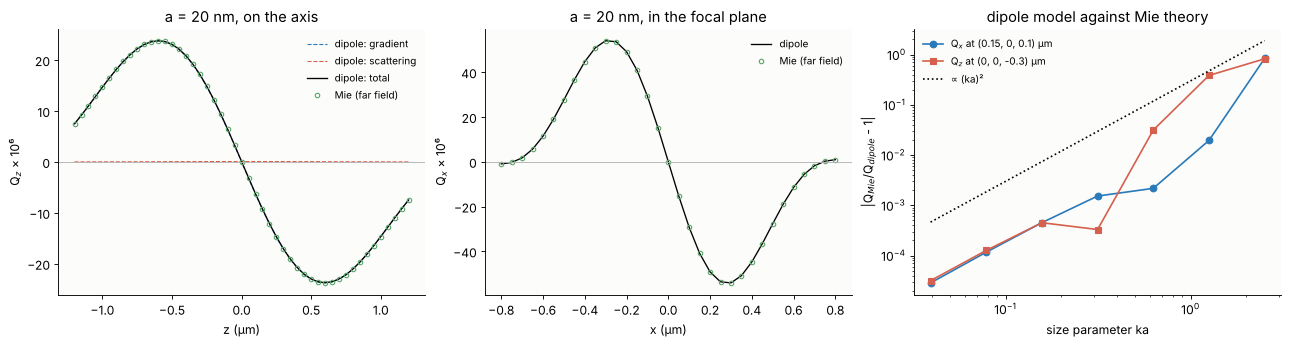

In [9]:
a_small = 20e-9
trap_s = wave_trap(a_small, max_offset=1.5*UM)
zs = np.linspace(-1.2, 1.2, 49)*UM
xs = np.linspace(-0.8, 0.8, 33)*UM
Qm_z = trap_s.force(on_axis(zs))[:, 2]
Qd_z, Qg_z, Qs_z = (q[:, 2] for q in tw.dipole_force(on_axis(zs), a_small, N_PS, WL, trap_s.plane_waves,
                                                     N_W, parts=True))
Qm_x = trap_s.force(along_x(xs))[:, 0]
Qd_x = tw.dipole_force(along_x(xs), a_small, N_PS, WL, trap_s.plane_waves, N_W)[:, 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
s = 1e6
ax[0].plot(zs/UM, Qg_z*s, color=BLUE, lw=1, ls="--", label="dipole: gradient")
ax[0].plot(zs/UM, Qs_z*s, color=RED, lw=1, ls="--", label="dipole: scattering")
ax[0].plot(zs/UM, Qd_z*s, color="k", lw=1.2, label="dipole: total")
ax[0].plot(zs/UM, Qm_z*s, "o", color=GREEN, mfc="none", ms=4, label="Mie (far field)")
ax[0].set_xlabel("z (µm)"); ax[0].set_ylabel("Q$_z$ × 10⁶"); ax[0].set_title("a = 20 nm, on the axis")
ax[0].legend(frameon=False, fontsize=9)
ax[1].plot(xs/UM, Qd_x*s, color="k", lw=1.2, label="dipole")
ax[1].plot(xs/UM, Qm_x*s, "o", color=GREEN, mfc="none", ms=4, label="Mie (far field)")
ax[1].set_xlabel("x (µm)"); ax[1].set_ylabel("Q$_x$ × 10⁶"); ax[1].set_title("a = 20 nm, in the focal plane")
ax[1].legend(frameon=False, fontsize=9)
for a_ in ax[:2]:
    a_.axhline(0, color="0.7", lw=0.8)
radii = np.array([5, 10, 20, 40, 80, 160, 320])*1e-9
probe = np.array([[0.15*UM, 0, 0.1*UM], [0, 0, -0.3*UM]])
dev = []
for a_r in radii:
    tr = wave_trap(a_r, max_offset=0.6*UM)
    qm = tr.force(probe)
    qd = tw.dipole_force(probe, a_r, N_PS, WL, tr.plane_waves, N_W)
    dev.append([abs(qm[0, 0]/qd[0, 0] - 1), abs(qm[1, 2]/qd[1, 2] - 1)])
dev = np.array(dev)
ka = 2*np.pi*N_W/WL*radii
ax[2].loglog(ka, dev[:, 0], "o-", color=BLUE, label="Q$_x$ at (0.15, 0, 0.1) µm")
ax[2].loglog(ka, dev[:, 1], "s-", color=RED, label="Q$_z$ at (0, 0, -0.3) µm")
ax[2].loglog(ka, 0.3*ka**2, ":", color="k", label="∝ (ka)²")
ax[2].set_xlabel("size parameter ka"); ax[2].set_ylabel("|Q$_{Mie}$/Q$_{dipole}$ - 1|")
ax[2].set_title("dipole model against Mie theory")
ax[2].legend(frameon=False, fontsize=9)
print("a = 20 nm: max deviation Mie - dipole = {:.1e} (largest |Q| = {:.1e})".format(
    max(np.abs(Qm_z - Qd_z).max(), np.abs(Qm_x - Qd_x).max()), np.abs(Qd_x).max()))

The small bead sits almost exactly in the focus: the scattering force is
weaker than the gradient force by about $(ka)^3$. Small beads are
trapped by the gradient force alone, as atoms and nanoparticles in an
optical dipole trap; the force scales with the volume, $a^3$.

**Check 2: large beads in a wide beam.** In a weakly focused beam much
wider than the bead, the bead in the focus sees a plane wave of intensity
$I_0$ and feels the radiation pressure $F = Q_{pr}\pi a^2n_mI_0/c$ with
$Q_{pr} = Q_{ext} - \langle\cos\Theta\rangle Q_{sca}$ from Mie theory
(`radiation_pressure_efficiency()`, van de Hulst). With a uniformly lit
pupil of NA 0.004 (an Airy spot of 160 µm radius) the far field momentum
balance reproduces it for beads up to 4 µm radius.

largest relative deviation: 1.9e-03


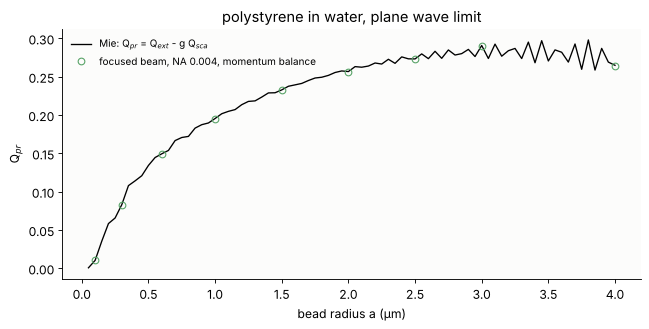

In [10]:
radii_pr = np.linspace(0.05, 4.0, 80)*UM
q_pr = np.array([tw.radiation_pressure_efficiency(a_r, N_PS, WL, N_W) for a_r in radii_pr])
radii_pts = np.array([0.1, 0.3, 0.6, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0])*UM
q_pts = []
for a_r in radii_pts:
    tr = wave_trap(a_r, NA=0.004, filling=None, max_offset=0.0)
    E0, _ = tw.focus_field(np.zeros(3), WL, tr.plane_waves, N_W)
    I_0 = N_W/(2*376.730313668)*np.sum(np.abs(E0)**2)
    P = tw.beam_power(tr.plane_waves, WL, N_W)
    q_pts.append(tr.force(np.zeros(3))[2]*P/(np.pi*a_r**2*I_0))
q_pts = np.array(q_pts)
q_pr_pts = np.array([tw.radiation_pressure_efficiency(a_r, N_PS, WL, N_W) for a_r in radii_pts])
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(radii_pr/UM, q_pr, color="k", lw=1.2, label="Mie: Q$_{pr}$ = Q$_{ext}$ - g Q$_{sca}$")
ax.plot(radii_pts/UM, q_pts, "o", color=GREEN, mfc="none", label="focused beam, NA 0.004, momentum balance")
ax.set_xlabel("bead radius a (µm)"); ax.set_ylabel("Q$_{pr}$")
ax.set_title("polystyrene in water, plane wave limit"); ax.legend(frameon=False, fontsize=9)
print("largest relative deviation: {:.1e}".format(np.max(np.abs(q_pts/q_pr_pts - 1))))

The remaining deviation (below $2\cdot10^{-3}$, growing as $a^2$) is the
intensity variation of the beam over the bead. The oscillations of $Q_{pr}$ come from
interference between light that passes through the bead and light that
passes it (as in the extinction paradox of notebook 71); a large bead
in a plane wave is simply pushed with $Q_{pr} \approx 0.1$ to $0.2$.

**Where the momentum goes.** The far field of the focused beam with and
without the bead (averaged over the azimuth) shows how the bead acts as
a small lens. Before the focus it bends the converging cone into a wider
outgoing cone: less forward momentum leaves, the bead is pushed forward.
Beyond the focus it collects the diverging light into a narrower cone:
more forward momentum leaves than came in, and the bead is pulled back.

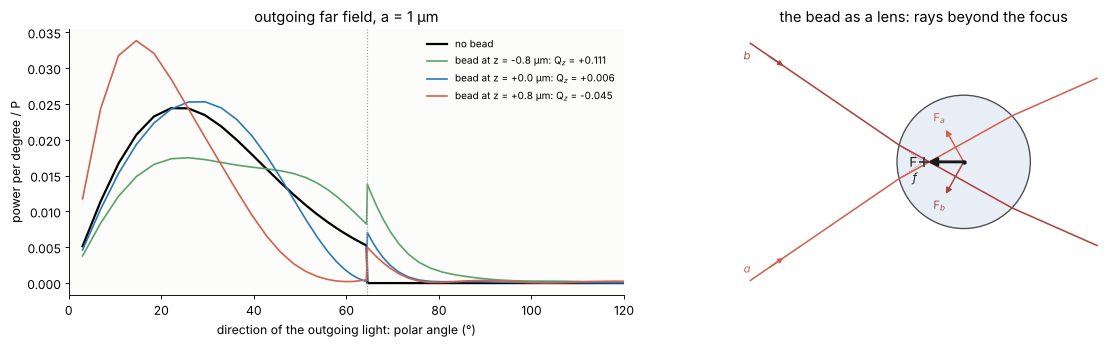

In [11]:
a_ff = 1.0*UM
trap_ff = wave_trap(a_ff, max_offset=1.2*UM)
u = trap_ff.directions_far
dO = trap_ff.solid_angles_far
uz = np.round(u[:, 2], 12)
rings = np.unique(uz)                  # the far field grids are rings of constant polar angle
th_ring = np.rad2deg(np.arccos(rings))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
I_inc = np.sum(np.abs(trap_ff.incident_far_field)**2, axis=1)
norm = np.sum(I_inc*dO)


def per_degree(I):
    """Power per degree of polar angle: sum over the ring times sin(theta) dphi."""
    return np.array([np.sum(I[uz == c])*2*np.pi/np.sum(uz == c) for c in rings]
                    )*np.sqrt(1 - rings**2)*np.pi/180/norm


ax[0].plot(th_ring, per_degree(I_inc), color="k", lw=2, label="no bead")
for zz, col in [(-0.8, GREEN), (0.0, BLUE), (0.8, RED)]:
    Fs = trap_ff.scattered_far_field(np.array([0, 0, zz*UM]))
    I_tot = np.sum(np.abs(trap_ff.incident_far_field + Fs)**2, axis=1)
    q = trap_ff.force(np.array([0, 0, zz*UM]))[2]
    ax[0].plot(th_ring, per_degree(I_tot), color=col, label="bead at z = {:+.1f} µm: Q$_z$ = {:+.3f}".format(zz, q))
ax[0].set_xlabel("direction of the outgoing light: polar angle (°)"); ax[0].set_ylabel("power per degree / P")
ax[0].set_xlim(0, 120); ax[0].legend(frameon=False, fontsize=9)
ax[0].axvline(np.rad2deg(np.arcsin(NA/N_W)), color="0.6", ls=":", lw=1)
ax[0].set_title("outgoing far field, a = 1 µm")
ax[1].set_title("the bead as a lens: rays beyond the focus")
sketch.ashkin_rays(ax[1], offset=(0.6, 0.0))

## 4. Rays against waves

The axial force on the axis and the lateral force through the axial
equilibrium, for polystyrene beads from 0.1 to 3 µm radius, in units of
the radius. Ray optics (black, dashed) is the same curve for all sizes.

a = 0.10 µm: z_eq = +1.226 a, largest backward Q_z = 0.002, largest restoring Q_x = 0.005


a = 0.25 µm: z_eq = +1.130 a, largest backward Q_z = 0.017, largest restoring Q_x = 0.073


a = 0.50 µm: z_eq = +0.342 a, largest backward Q_z = 0.053, largest restoring Q_x = 0.249


a = 1.00 µm: z_eq = +0.072 a, largest backward Q_z = 0.061, largest restoring Q_x = 0.433


a = 2.00 µm: z_eq = +0.100 a, largest backward Q_z = 0.066, largest restoring Q_x = 0.546


a = 3.00 µm: z_eq = +0.209 a, largest backward Q_z = 0.068, largest restoring Q_x = 0.517
ray optics:  z_eq = +0.275 a, largest backward Q_z = 0.076, largest restoring Q_x = 0.451
wave model for six bead sizes: 111 s


Text(0, 0.5, 'Q$_x$ at z$_{eq}$')

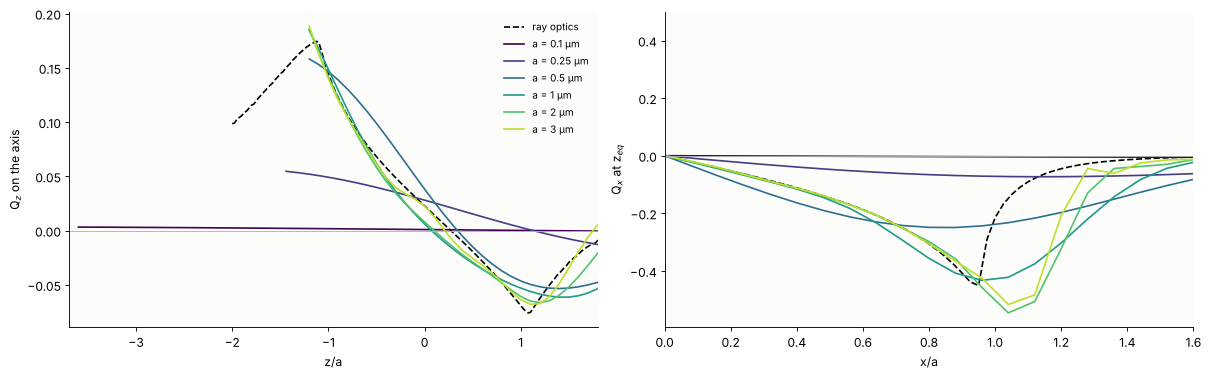

In [12]:
radii_cmp = np.array([0.1, 0.25, 0.5, 1.0, 2.0, 3.0])*UM
cols = colormaps["viridis"](np.linspace(0, 0.9, len(radii_cmp)))
zc = np.linspace(-1.2, 1.8, 31)
xc = np.linspace(0, 1.6, 21)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
qz_ray, qx_ray, _, zeq_ray = ray_curves[1.0]
ax[0].plot(z_r, qz_ray, "k--", lw=1.5, label="ray optics")
ax[1].plot(x_r, qx_ray, "k--", lw=1.5, label="ray optics")
traps, eq_wave = {}, {}
t0 = time.time()
for a_r, col in zip(radii_cmp, cols):
    tr = wave_trap(a_r, max_offset=max(1.8*a_r, 0.6*UM))
    traps[a_r] = tr
    qz = tr.force(on_axis(zc*a_r if a_r > 0.3*UM else zc*0.3*UM))[:, 2]
    zz = zc*a_r if a_r > 0.3*UM else zc*0.3*UM
    i = np.nonzero((qz[:-1] > 0) & (qz[1:] <= 0))[0][0]
    z_eq = tw.equilibrium(lambda z: tr.force(np.array([0, 0, z]))[2], zz[i], zz[i + 1], num=2)
    qx = tr.force(along_x(xc*a_r, z_eq))[:, 0]
    eq_wave[a_r] = z_eq
    ax[0].plot(zz/a_r, qz, color=col, label="a = {:g} µm".format(a_r/UM))
    ax[1].plot(xc, qx, color=col)
    print("a = {:4.2f} µm: z_eq = {:+.3f} a, largest backward Q_z = {:.3f}, largest restoring Q_x = {:.3f}".format(
        a_r/UM, z_eq/a_r, -qz.min(), -qx.min()))
print("ray optics:  z_eq = {:+.3f} a, largest backward Q_z = {:.3f}, largest restoring Q_x = {:.3f}".format(
    zeq_ray, -qz_ray.min(), qx_ray.max()))
print("wave model for six bead sizes: {:.0f} s".format(time.time() - t0))
for a_ in ax:
    a_.axhline(0, color="0.7", lw=0.8)
ax[0].set_xlim(-3.7, 1.8)
ax[0].set_xlabel("z/a"); ax[0].set_ylabel("Q$_z$ on the axis"); ax[0].legend(frameon=False, fontsize=9)
ax[1].set_xlim(0, 1.6)
ax[1].set_xlabel("x/a"); ax[1].set_ylabel("Q$_x$ at z$_{eq}$")

For beads of 2 to 3 µm radius the wave model approaches the ray optics
curves: the equilibrium position, the largest lateral efficiency and the
shape of the axial curve agree within some 10 to 20 %; the oscillations
around the ray optics curve are interference between light that passes
through the bead and around it, which decays only slowly with the size.
Small beads ($a \lesssim 0.25$ µm) have curves that are wider than the
bead and much smaller efficiencies (the force is that on a dipole,
$\propto a^3$, divided by the momentum flux that would hit a disk of
radius $a$, $\propto a^2$). In between, near $a \approx \lambda/n_m$,
the bead is as wide as the focus and the efficiencies approach those of
ray optics. Small beads sit about one radius beyond the focus, 1 µm
beads almost in it.

## 5. Potential wells and Brownian motion

Along the axis and across it the force has a potential,
$U(z) = -\int F_z\,dz$. With $P = 5$ mW at the bead, a 0.5 µm
bead sits in a well that is about 800 $k_BT$ deep across the axis but
only about 260 $k_BT$ along it towards $+z$, where the scattering force
pushes it out of the focus over a barrier.

axial equilibrium z_eq = 171 nm, axial barrier 258.1 kT, lateral depth 788 kT (x), 764 kT (y)


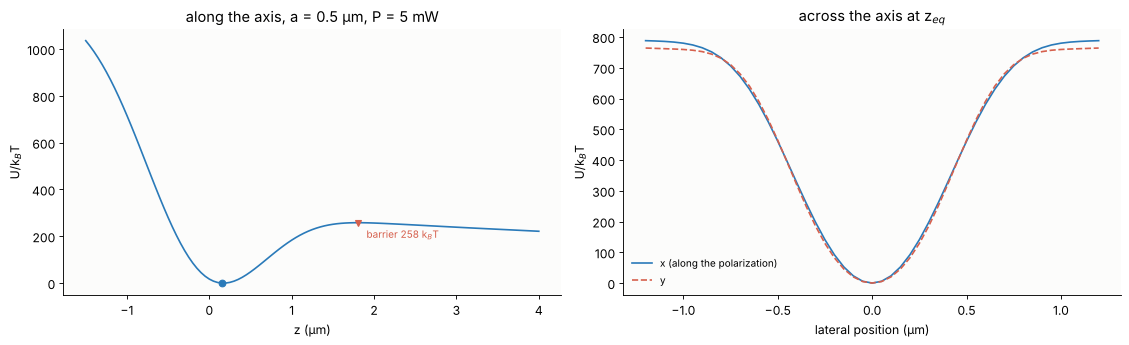

In [13]:
a5 = 0.5*UM
tr5 = wave_trap(a5, max_offset=4.0*UM)
z5 = np.linspace(-1.5, 4.0, 111)*UM
q5z = tr5.force(on_axis(z5))[:, 2]
z_eq5 = eq_wave.get(a5)
x5 = np.linspace(-1.2, 1.2, 49)*UM
q5x = tr5.force(along_x(x5, z_eq5))[:, 0]
q5y = tr5.force(along_x(x5, z_eq5, axis=1))[:, 1]
P5 = 5e-3
U_z = -cumulative_trapezoid(q5z*UNIT*P5, z5, initial=0)/KT
U_x = -cumulative_trapezoid(q5x*UNIT*P5, x5, initial=0)/KT
U_y = -cumulative_trapezoid(q5y*UNIT*P5, x5, initial=0)/KT
i_eq = np.argmin(U_z)
U_z -= U_z[i_eq]
U_x -= U_x[len(x5)//2]
U_y -= U_y[len(x5)//2]
i_b = i_eq + np.argmax(U_z[i_eq:])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
ax[0].plot(z5/UM, U_z, color=BLUE)
ax[0].plot(z5[i_eq]/UM, 0, "o", color=BLUE)
ax[0].plot(z5[i_b]/UM, U_z[i_b], "v", color=RED)
ax[0].annotate("barrier {:.0f} k$_B$T".format(U_z[i_b]), (z5[i_b]/UM, U_z[i_b]), textcoords="offset points",
               xytext=(8, -14), color=RED, fontsize=9)
ax[0].set_xlabel("z (µm)"); ax[0].set_ylabel("U/k$_B$T"); ax[0].set_title("along the axis, a = 0.5 µm, P = 5 mW")
ax[1].plot(x5/UM, U_x, color=BLUE, label="x (along the polarization)")
ax[1].plot(x5/UM, U_y, color=RED, ls="--", label="y")
ax[1].set_xlabel("lateral position (µm)"); ax[1].set_ylabel("U/k$_B$T")
ax[1].set_title("across the axis at z$_{eq}$"); ax[1].legend(frameon=False, fontsize=9)
print("axial equilibrium z_eq = {:.0f} nm, axial barrier {:.1f} kT, lateral depth {:.0f} kT (x), {:.0f} kT (y)".format(
    z_eq5*1e9, U_z[i_b], U_x[[0, -1]].min(), U_y[[0, -1]].min()))

**Calibration by the power spectrum.** In the harmonic part of the well a
bead with friction $\gamma = 6\pi\eta a$ moves as an overdamped Brownian
particle, $\gamma\dot x = -\kappa x + \sqrt{2k_BT\gamma}\,\xi(t)$
(`brownian_trajectory()`). Its position has the variance
$\langle x^2\rangle = k_BT/\kappa$ (equipartition) and the Lorentzian
power spectrum $S(f) = k_BT/(\pi^2\gamma(f_c^2 + f^2))$ with the corner
frequency $f_c = \kappa/(2\pi\gamma)$ (`lorentzian_psd()`). Measuring
$f_c$ with a quadrant photodiode calibrates the trap without knowing the
laser power at the bead (Berg-Sørensen and Flyvbjerg 2004). The
simulation uses the spring constants of the wave model at 20 mW.

spring constants (wave model, 20 mW): κ = [77.4 65.1 17.9] pN/µm, corner frequencies [1376. 1157.  319.] Hz
x: f_c fitted   1386 Hz (true   1376), κ from equipartition 76.4 pN/µm (true 77.4)


y: f_c fitted   1165 Hz (true   1157), κ from equipartition 64.3 pN/µm (true 65.1)
z: f_c fitted    326 Hz (true    319), κ from equipartition 18.3 pN/µm (true 17.9)


Text(0.5, 1.0, 'power spectra of x, y, z')

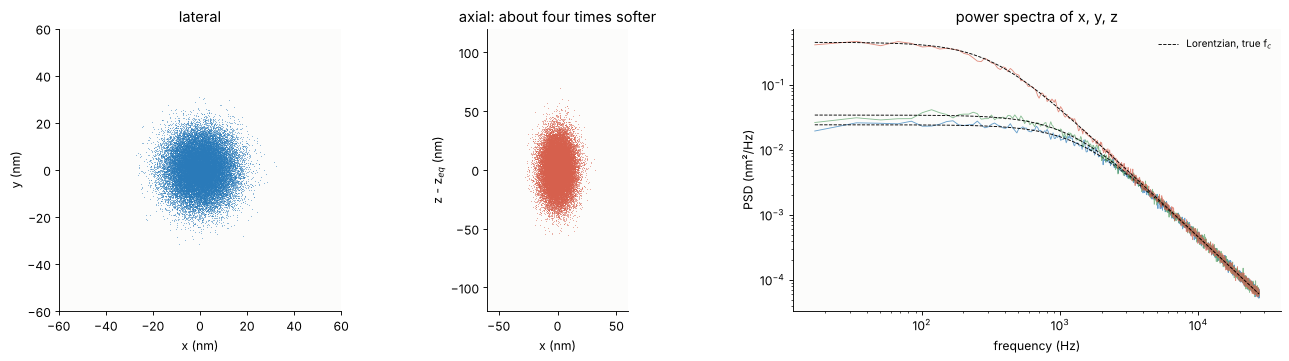

In [14]:
P_cal = 20e-3
kappa5 = tw.stiffness(tr5.force, [0, 0, z_eq5], 10e-9)*UNIT*P_cal
gamma5 = 6*np.pi*ETA*a5
fc = kappa5/(2*np.pi*gamma5)
dt = 1/(400*fc.max())
n_steps = 2**21
traj = tw.brownian_trajectory(lambda r: -kappa5*r, np.zeros(3), gamma5, T_K, dt, n_steps, rng)
print("spring constants (wave model, 20 mW): κ = {} pN/µm, corner frequencies {} Hz".format(
    np.round(kappa5*1e6, 1), np.round(fc, 0)))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), layout="constrained", width_ratios=[1, 1, 1.4])
ax[0].plot(traj[::64, 0]*1e9, traj[::64, 1]*1e9, ",", color=BLUE, alpha=0.5)
ax[0].set_xlabel("x (nm)"); ax[0].set_ylabel("y (nm)"); ax[0].set_aspect("equal"); ax[0].set_title("lateral")
ax[1].plot(traj[::64, 0]*1e9, traj[::64, 2]*1e9, ",", color=RED, alpha=0.5)
ax[1].set_xlabel("x (nm)"); ax[1].set_ylabel("z - z$_{eq}$ (nm)"); ax[1].set_aspect("equal")
ax[1].set_title("axial: about four times softer")
for a_ in ax[:2]:
    a_.set_xlim(-60, 60); a_.set_ylim(-60 if a_ is ax[0] else -120, 60 if a_ is ax[0] else 120)
for l, (col, name) in enumerate([(BLUE, "x"), (GREEN, "y"), (RED, "z")]):
    f, S = welch(traj[:, l], fs=1/dt, nperseg=2**15)
    keep = (f > 0) & (f < 20*fc.max())
    popt, _ = curve_fit(lambda ff, fcf, D: np.log(D/(fcf**2 + ff**2)), f[keep], np.log(S[keep]),
                        p0=[fc[l], KT/(np.pi**2*gamma5)])
    ax[2].loglog(f[keep], S[keep]*1e18, color=col, lw=0.8, alpha=0.7)
    ax[2].loglog(f[keep], tw.lorentzian_psd(f[keep], fc[l], gamma5, T_K)*1e18, color="k", lw=0.8, ls="--")
    var = np.var(traj[n_steps//10:, l])
    print("{}: f_c fitted {:6.0f} Hz (true {:6.0f}), κ from equipartition {:.1f} pN/µm (true {:.1f})".format(
        name, popt[0], fc[l], KT/var*1e6, kappa5[l]*1e6))
ax[2].plot([], [], "k--", lw=0.8, label="Lorentzian, true f$_c$")
ax[2].set_xlabel("frequency (Hz)"); ax[2].set_ylabel("PSD (nm²/Hz)"); ax[2].legend(frameon=False, fontsize=9)
ax[2].set_title("power spectra of x, y, z")

Equipartition and the corner frequency recover the spring constants to
about a per cent. The time step must be well below the relaxation time
$\gamma/\kappa$: the Euler scheme lowers the variance by the factor
$1 - \kappa\Delta t/2\gamma$ (here 0.8 %). (A real
calibration also has to handle the photodiode's filtering, aliasing and the
hydrodynamics near the coverslip; see Berg-Sørensen and Flyvbjerg.)

**Escape over the axial barrier.** At low power the barrier is a few
$k_BT$ and the bead leaves the trap by a thermal fluctuation. Along the
axis the force is conservative, and the mean time to cross a barrier
$\Delta U \gg k_BT$ is Kramers' result
$\tau = 2\pi\gamma/\sqrt{\kappa_{eq}|\kappa_b|}\;e^{\Delta U/k_BT}$, with the
curvatures at the bottom and the top. 300 beads per power follow the
axial force of the wave model (a 1D Langevin simulation on the axis)
until they are 1 µm past the barrier.

P = 0.058 mW, ΔU = 3.0 kT: escape after 57.86 ± 3.31 s, Kramers 72.06 s
P = 0.077 mW, ΔU = 4.0 kT: escape after 126.04 ± 7.32 s, Kramers 146.91 s
P = 0.097 mW, ΔU = 5.0 kT: escape after 282.34 ± 16.03 s, Kramers 319.48 s
P = 0.116 mW, ΔU = 6.0 kT: escape after 674.54 ± 37.02 s, Kramers 723.69 s


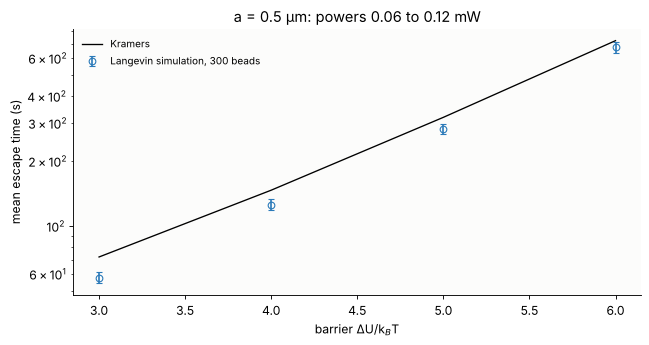

In [15]:
F_spline = CubicSpline(z5, q5z*UNIT)
dF = F_spline.derivative()
z_b = z5[i_b]
kap_eq, kap_b = -dF(z_eq5), dF(z_b)        # per watt
U_barrier_W = -float(F_spline.integrate(z_eq5, z_b))     # barrier height per watt (J/W)
powers = np.array([3.0, 4.0, 5.0, 6.0])*KT/U_barrier_W
n_beads = 300
t_sim, t_kr = [], []
for P in powers:
    dt_e = 0.04*gamma5/(kap_eq*P)
    z = np.full(n_beads, z_eq5)
    t_esc = np.full(n_beads, np.nan)
    sig = np.sqrt(2*KT*dt_e/gamma5)
    step = 0
    while np.isnan(t_esc).any() and step < 4_000_000:
        live = np.isnan(t_esc)
        z[live] += F_spline(np.clip(z[live], z5[0], z5[-1]))*P*dt_e/gamma5 + sig*rng.standard_normal(live.sum())
        step += 1
        out = live & (z > z_b + 1.0*UM)
        t_esc[out] = step*dt_e
    t_sim.append([np.nanmean(t_esc), np.nanstd(t_esc)/np.sqrt(np.sum(~np.isnan(t_esc)))])
    t_kr.append(2*np.pi*gamma5/(P*np.sqrt(kap_eq*kap_b))*np.exp(U_barrier_W*P/KT))
t_sim, t_kr = np.array(t_sim), np.array(t_kr)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
dU = U_barrier_W*powers/KT
ax.semilogy(dU, t_kr, color="k", lw=1.2, label="Kramers")
ax.errorbar(dU, t_sim[:, 0], t_sim[:, 1], fmt="o", color=BLUE, mfc="none", capsize=3,
            label="Langevin simulation, 300 beads")
ax.set_xlabel("barrier ΔU/k$_B$T"); ax.set_ylabel("mean escape time (s)")
ax.set_title("a = 0.5 µm: powers {:.2f} to {:.2f} mW".format(powers[0]*1e3, powers[-1]*1e3))
ax.legend(frameon=False, fontsize=9)
for P, ts, tk in zip(powers, t_sim, t_kr):
    print("P = {:.3f} mW, ΔU = {:.1f} kT: escape after {:.2f} ± {:.2f} s, Kramers {:.2f} s".format(
        P*1e3, U_barrier_W*P/KT, ts[0], ts[1], tk))

Kramers' formula, an asymptotic result for high barriers, is within
about 10 to 20 % of the simulation already at 3 to 4 $k_BT$ and approaches
it for higher barriers. The escape time grows by $e$ per $k_BT$: a bead
that leaves within seconds at 0.1 mW stays for the age of the universe at
5 mW. Optical tweezers lose beads not by thermal escape but because of
collisions, aberrations deep in the sample, or a trap that is not a trap
at all (section 7).

## 6. Trap stiffness against bead size and NA

The spring constants $\kappa = -\partial F/\partial x$ at the
equilibrium, per watt, for polystyrene beads of 50 nm to 3 µm radius. For
small beads they follow the dipole model ($\propto a^3$, here the
gradient force alone at the focus), for large beads ray optics
($\kappa = n_mP/c \cdot Q'/a \propto 1/a$). Between the two, near
$a \approx 0.4$ µm, the stiffness is largest; that is why beads of
about 1 µm diameter are the workhorse of single molecule experiments.

wave model stiffness for 13 bead sizes: 66 s
largest lateral stiffness 3889 pN/µm per W at a = 0.40 µm (κ_x/κ_z = 4.6)


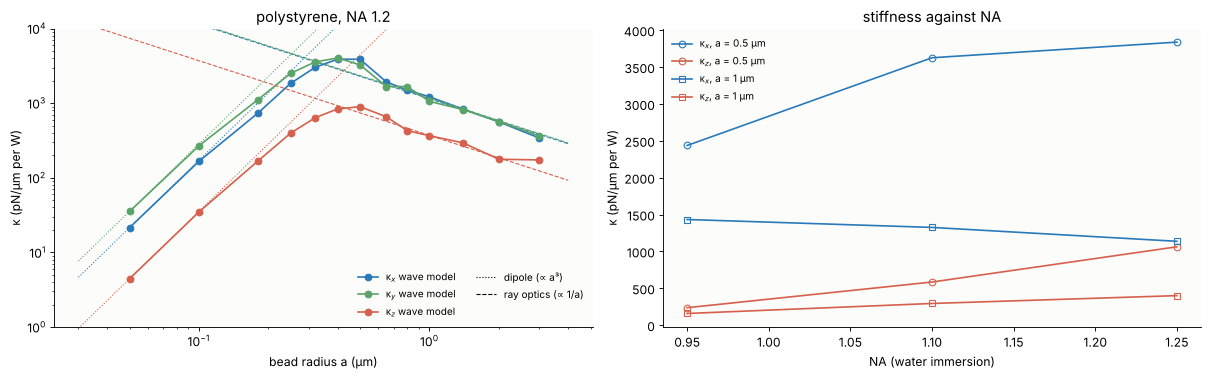

In [16]:
radii_k = np.array([0.05, 0.1, 0.18, 0.25, 0.32, 0.4, 0.5, 0.65, 0.8, 1.0, 1.4, 2.0, 3.0])*UM
t0 = time.time()
kap_w, zeq_w = [], []
for a_r in radii_k:
    tr = traps.get(a_r) or wave_trap(a_r, max_offset=max(1.5*a_r, 0.6*UM))
    z_eq, kap = trap_point(tr.force, a_r)
    kap_w.append(kap*UNIT)
    zeq_w.append(z_eq)
kap_w = np.array(kap_w)
print("wave model stiffness for {} bead sizes: {:.0f} s".format(len(radii_k), time.time() - t0))
# ray optics: Q' in units of 1/a
z_eq_r = ray_curves[1.0][3]
kap_ray = tw.stiffness(lambda r: tw.ray_optics_force(r, 1.0, N_PS, NA, N_W), [0, 0, z_eq_r], 0.01)*UNIT
# dipole: gradient force of a point at the focus
pw_d = tw.focus_plane_waves(NA, N_W, 40, 96, FILL, "x")
kap_dip = tw.stiffness(lambda r: tw.dipole_force(r, 1e-9, N_PS, WL, pw_d, N_W), [0, 0, 0], 5e-9)*UNIT/1e-27
a_plot = np.logspace(np.log10(0.03), np.log10(4), 100)*UM
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for l, (col, name) in enumerate([(BLUE, "x"), (GREEN, "y"), (RED, "z")]):
    ax[0].loglog(radii_k/UM, kap_w[:, l]*1e6, "o-", color=col, label="κ$_{}$ wave model".format(name))
    ax[0].loglog(a_plot/UM, kap_dip[l]*a_plot**3*1e6, ":", color=col, lw=1)
    ax[0].loglog(a_plot/UM, kap_ray[l]/a_plot*1e6, "--", color=col, lw=1)
ax[0].plot([], [], "k:", lw=1, label="dipole (∝ a³)")
ax[0].plot([], [], "k--", lw=1, label="ray optics (∝ 1/a)")
ax[0].set_ylim(1, 1e4)
ax[0].set_xlabel("bead radius a (µm)"); ax[0].set_ylabel("κ (pN/µm per W)")
ax[0].set_title("polystyrene, NA 1.2"); ax[0].legend(frameon=False, fontsize=9, ncol=2)
i_max = np.argmax(kap_w[:, 0])
print("largest lateral stiffness {:.0f} pN/µm per W at a = {:.2f} µm (κ_x/κ_z = {:.1f})".format(
    kap_w[i_max, 0]*1e6, radii_k[i_max]/UM, kap_w[i_max, 0]/kap_w[i_max, 2]))

NAs = np.array([0.8, 0.95, 1.1, 1.25])
kap_na = {}
for a_r, mk in [(0.5*UM, "o"), (1.0*UM, "s")]:
    res = []
    for na in NAs:
        tr = wave_trap(a_r, NA=na, max_offset=2.5*a_r)
        res.append(trap_point(tr.force, a_r, z_hi=2.5*a_r + 0.6*UM)[1]*UNIT)
    kap_na[a_r] = np.array(res)
    for l, col in [(0, BLUE), (2, RED)]:
        ax[1].plot(NAs, kap_na[a_r][:, l]*1e6, mk + "-", color=col, mfc="none",
                   label="κ$_{}$, a = {:g} µm".format("xz"[l//2], a_r/UM))
ax[1].set_xlabel("NA (water immersion)"); ax[1].set_ylabel("κ (pN/µm per W)")
ax[1].set_title("stiffness against NA"); ax[1].legend(frameon=False, fontsize=9)

The lateral stiffness peaks at about 4 pN/nm per W for $a \approx 0.4$ µm
(an ideal, aberration free focus; measured values are typically several
times lower)
and depends only mildly on the NA; the axial stiffness is three to five
times smaller and drops steeply with the NA (a 0.5 µm bead is no longer
trapped at NA 0.8, see section 7). For large beads the
x and y spring constants differ by a few per cent (polarization), and the
wave model oscillates around the ray optics line, slowly approaching it.

## 7. When the bead escapes: low NA, underfilled pupils and high index

A trap exists only if the axial force somewhere beyond the focus points
backwards. The largest backward efficiency $-\min Q_z$ is the figure of
merit: it sets how strongly the bead can be pulled against a flow or a
molecule. For a 1 µm bead at an NA of 0.8 and below, the scattering
force wins everywhere on the axis and the bead is blown out of the
focus; ray optics still traps it down to an NA of about 0.55. A 1 µm bead
with $n = 1.85$ is still held at NA 1.2, one with $n = 2$ is not. The same happens for
beads of high index: they reflect more and refract the steep rays less
favourably (section 1).

a = 1 µm, NA 0.5: min Q_z = +0.049 (waves), +0.002 (rays)


a = 1 µm, NA 0.6: min Q_z = +0.021 (waves), -0.007 (rays)


a = 1 µm, NA 0.7: min Q_z = +0.007 (waves), -0.016 (rays)


a = 1 µm, NA 0.8: min Q_z = +0.000 (waves), -0.026 (rays)


a = 1 µm, NA 1.0: min Q_z = -0.034 (waves), -0.049 (rays)


a = 1 µm, NA 1.2: min Q_z = -0.061 (waves), -0.076 (rays)


... (4 outputs left out)

a = 1 µm, n = 2.00: min Q_z = +0.049


a = 1 µm, n = 2.20: min Q_z = +0.191


a = 1 µm, n = 2.40: min Q_z = +0.089


ray optics, polystyrene: trapped for NA > 0.50
run time: 469 s


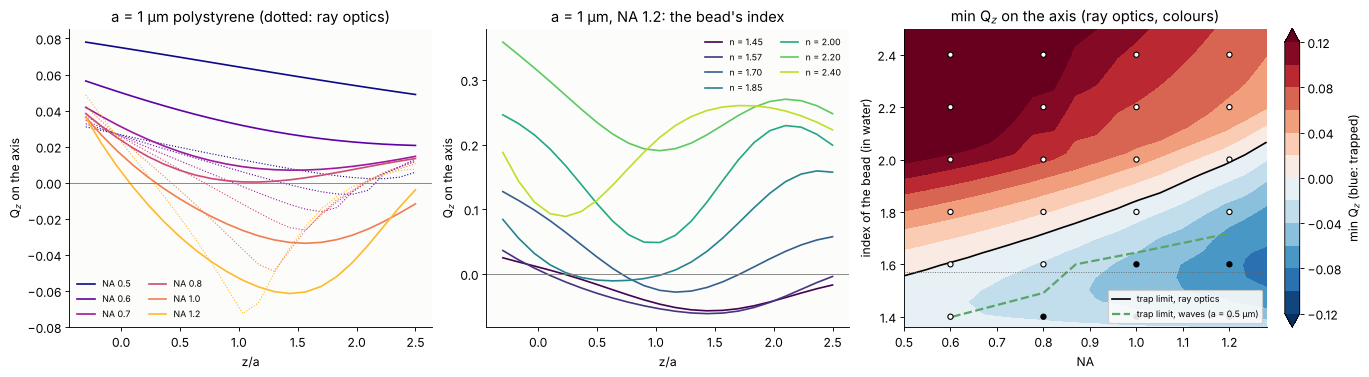

In [17]:
z_scan = np.linspace(-0.3, 2.5, 22)
NA_scan = np.array([0.5, 0.6, 0.7, 0.8, 1.0, 1.2])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
colsNA = colormaps["plasma"](np.linspace(0, 0.85, len(NA_scan)))
a7 = 1.0*UM
for na, col in zip(NA_scan, colsNA):
    tr = wave_trap(a7, NA=na, max_offset=2.5*a7)
    qz = tr.force(on_axis(z_scan*a7))[:, 2]
    ax[0].plot(z_scan, qz, color=col, label="NA {:.1f}".format(na))
    print("a = 1 µm, NA {:.1f}: min Q_z = {:+.3f} (waves), {:+.3f} (rays)".format(
        na, qz.min(), tw.ray_optics_force(on_axis(np.linspace(0, 4, 41)), 1.0, N_PS, na, N_W)[:, 2].min()))
    qr = tw.ray_optics_force(on_axis(z_scan), 1.0, N_PS, na, N_W)[:, 2]
    ax[0].plot(z_scan, qr, color=col, ls=":", lw=1)
ax[0].axhline(0, color="0.5", lw=0.8)
ax[0].set_xlabel("z/a"); ax[0].set_ylabel("Q$_z$ on the axis")
ax[0].set_title("a = 1 µm polystyrene (dotted: ray optics)"); ax[0].legend(frameon=False, fontsize=8, ncol=2)

n_scan = np.array([1.45, 1.57, 1.70, 1.85, 2.0, 2.2, 2.4])
for n_b, col in zip(n_scan, colormaps["viridis"](np.linspace(0, 0.9, len(n_scan)))):
    tr = wave_trap(a7, n_sph=n_b, max_offset=2.5*a7)
    qz = tr.force(on_axis(z_scan*a7))[:, 2]
    ax[1].plot(z_scan, qz, color=col, label="n = {:.2f}".format(n_b))
    print("a = 1 µm, n = {:.2f}: min Q_z = {:+.3f}".format(n_b, qz.min()))
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set_xlabel("z/a"); ax[1].set_ylabel("Q$_z$ on the axis")
ax[1].set_title("a = 1 µm, NA 1.2: the bead's index"); ax[1].legend(frameon=False, fontsize=8, ncol=2)

# trapping map (largest backward efficiency) in ray optics and with waves for a = 0.5 um
na_m = np.linspace(0.5, 1.28, 18)
n_m = np.linspace(1.36, 2.5, 25)
z_m = np.linspace(-0.3, 4.0, 36)
qmin_ray = np.array([[tw.ray_optics_force(on_axis(z_m), 1.0, nb, na, N_W, num_theta=60, num_phi=48)[:, 2].min()
                      for na in na_m] for nb in n_m])
na_w = np.array([0.6, 0.8, 1.0, 1.2])
n_w = np.array([1.4, 1.6, 1.8, 2.0, 2.2, 2.4])
qmin_w = np.array([[wave_trap(0.5*UM, n_sph=nb, NA=na, max_offset=2.0*UM).force(on_axis(np.linspace(-0.2, 2.0, 23)*UM))[:, 2].min()
                    for na in na_w] for nb in n_w])
lev = np.linspace(-0.12, 0.12, 13)
cs = ax[2].contourf(na_m, n_m, qmin_ray, lev, cmap="RdBu_r", extend="both")
ax[2].contour(na_m, n_m, qmin_ray, [0], colors="k", linewidths=1.5)
ax[2].contour(na_w, n_w, qmin_w, [0], colors=GREEN, linewidths=2, linestyles="--")
NW, NN = np.meshgrid(na_w, n_w)
ax[2].scatter(NW.ravel(), NN.ravel(), c=np.where(qmin_w < 0, "k", "white").ravel(), edgecolors="k", s=22, zorder=4)
ax[2].plot([], [], "k-", label="trap limit, ray optics")
ax[2].plot([], [], "--", color=GREEN, lw=2, label="trap limit, waves (a = 0.5 µm)")
ax[2].axhline(N_PS, color="0.4", lw=0.8, ls=":")
ax[2].set_xlabel("NA"); ax[2].set_ylabel("index of the bead (in water)")
ax[2].set_title("min Q$_z$ on the axis (ray optics, colours)")
ax[2].legend(frameon=True, framealpha=0.9, fontsize=8, loc="lower right")
plt.colorbar(cs, ax=ax[2], label="min Q$_z$ (blue: trapped)")
print("ray optics, polystyrene: trapped for NA > {:.2f}".format(
    na_m[np.argmax(qmin_ray[np.argmin(np.abs(n_m - N_PS))] < 0)]))
print("run time: {:.0f} s".format(time.time() - t_start))

Blue means a backward axial force somewhere beyond the focus (a trap),
red that the bead is blown away. Ray optics traps polystyrene above an NA
of about 0.5 and no bead with an index above about 2 at any NA, in
water. The wave model (green line; filled dots trapped, open dots not) is
much stricter for a 0.5 µm bead: polystyrene needs an NA of about 0.9,
and beads above $n \approx 1.7$ escape even at NA 1.2. Wavelength sized
beads scatter more light forward than ray optics allows for. Titania
and diamond beads are trapped only with anti-reflection coatings or as
very small particles. Air bubbles and
droplets of lower index than water are pushed out of the focus sideways
and need a doughnut beam (notebook 69). In real instruments the
objective is often an oil immersion lens that focuses through the coverslip into water; the spherical
aberration of that interface stretches the focus and limits the depth at
which beads can be held (not modelled here).

## Summary

- **One ray** (`ashkin_efficiencies()`, `traced_efficiencies()`): the
  scattering and gradient efficiencies of a ray hitting a sphere, summed
  over all internal reflections in closed form, agree with an explicit
  trace of 200 reflections to round-off.
- **Ray optics** (`ray_optics_force()`): an aplanatic NA 1.2 water
  immersion objective holds polystyrene beads slightly beyond the focus.
  The steep rays pull, the central ones push; overfilling the pupil makes
  the trap stronger, underfilling it weak and far from the focus.
- **Waves** (`focus_plane_waves()`, `MieTrap`): the Richards–Wolf focus
  as a plane wave quadrature, each plane wave scattered exactly (Mie), and
  the force from the momentum lost in the far field (the stress tensor at
  infinity). It agrees with the **dipole force** (`dipole_force()`) for
  small beads with a deviation $\propto(ka)^2$, and with the **radiation
  pressure** $Q_{pr}$ of Mie theory (`radiation_pressure_efficiency()`) in a
  weakly focused beam.
- **Rays against waves:** for radii of 2 to 3 µm the wave model is close to
  ray optics; beads of the size of the wavelength have the largest
  efficiencies and the largest **stiffness** (about 4 pN/nm per W
  laterally at $a \approx 0.4$ µm, three to five times less axially),
  which falls as $a^3$ for small and as $1/a$ for large beads.
- **Brownian motion** (`brownian_trajectory()`, `lorentzian_psd()`):
  equipartition and the corner frequency of the Lorentzian power spectrum
  recover the spring constants; the **thermal escape** time over the
  axial barrier follows Kramers' rate.
- **Escape:** low NA, underfilled pupils and high index beads leave the
  axial force positive everywhere and the bead is blown out of the trap.

## References

- A. Ashkin, "Acceleration and trapping of particles by radiation pressure", Phys. Rev. Lett. 24, 156-159 (1970).
- A. Ashkin, J. M. Dziedzic, J. E. Bjorkholm and S. Chu, "Observation of a single-beam gradient force optical trap for dielectric particles", Opt. Lett. 11, 288-290 (1986).
- A. Ashkin, "Forces of a single-beam gradient laser trap on a dielectric sphere in the ray optics regime", Biophys. J. 61, 569-582 (1992).
- B. Richards and E. Wolf, "Electromagnetic diffraction in optical systems II. Structure of the image field in an aplanatic system", Proc. R. Soc. Lond. A 253, 358-379 (1959).
- C. F. Bohren and D. R. Huffman, Absorption and Scattering of Light by Small Particles, Wiley (1983), chapter 4.
- H. C. van de Hulst, Light Scattering by Small Particles, Wiley (1957), chapter 6 (radiation pressure).
- G. Gouesbet and G. Gréhan, Generalized Lorenz-Mie Theories, 2nd ed., Springer (2017).
- P. C. Chaumet and M. Nieto-Vesperinas, "Time-averaged total force on a dipolar sphere in an electromagnetic field", Opt. Lett. 25, 1065-1067 (2000).
- T. A. Nieminen, V. L. Y. Loke, A. B. Stilgoe, G. Knöner, A. M. Brańczyk, N. R. Heckenberg and H. Rubinsztein-Dunlop, "Optical tweezers computational toolbox", J. Opt. A 9, S196-S203 (2007).
- K. Berg-Sørensen and H. Flyvbjerg, "Power spectrum analysis for optical tweezers", Rev. Sci. Instrum. 75, 594-612 (2004).
- H. A. Kramers, "Brownian motion in a field of force and the diffusion model of chemical reactions", Physica 7, 284-304 (1940).
- K. C. Neuman and S. M. Block, "Optical trapping", Rev. Sci. Instrum. 75, 2787-2809 (2004).
- P. H. Jones, O. M. Maragò and G. Volpe, Optical Tweezers: Principles and Applications, Cambridge University Press (2015).